# Laboratory Exercise: Image Classification Using Pre-trained Models

## 1. Introduction

Image classification is the task of teaching a computer to look at a picture and decide what it shows, such as a church, a parachute, or a garbage truck. It is one of the most common problems in computer vision and the basis for many real-world tools, from photo organizers to quality inspection systems.

Training a model from scratch takes a large amount of data, time, and computing power. A practical alternative is to use **pre-trained models**: networks that have already learned to recognize visual patterns from millions of images. PyTorch's `torchvision.models` library provides many of these, trained on **ImageNet-1k**, a large benchmark dataset with 1,000 object categories. Because they are ready to use, it is easier to test how well they perform on new images without training them again.

In this laboratory exercise, I evaluate five pre-trained models with different designs: **ResNet-50, DenseNet-121, MobileNetV3-Large, EfficientNet-B0, and ViT-B/16**. They range from lightweight models built for mobile devices to larger models and a transformer-based model. These modeles were on **Imagenette**, a curated subset of ImageNet containing 10 easily distinguishable classes. Since these classes also exist in ImageNet-1k, the models can be evaluated directly without fine-tuning.

The exercise has three main goals:

1. **Build a complete evaluation pipeline** in PyTorch, including a custom `Dataset` class and `DataLoader` objects that prepare images the way each model expects.
2. **Measure performance fairly** using accuracy, precision, recall, and F1-score, along with model size and inference speed.
3. **Interpret the results** by explaining why the models performed differently, considering their architecture, complexity, input requirements, and suitability for the dataset.

The notebook follows this workflow: dataset curation, custom `Dataset` and `DataLoader`, model inference, metric computation, comparison through tables and charts, and a final analysis and conclusion.

## 2. Setup

In [1]:
import os, time, random, tarfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__, "| device:", DEVICE)

PyTorch: 2.11.0+cu130 | torchvision: 0.26.0+cu130 | device: cuda


## 3. Dataset Curation

**Dataset:** [Imagenette](https://github.com/fastai/imagenette), a curated subset of 10 easily classified ImageNet classes.

The pre-trained models were trained on ImageNet-1k, so each of the 10 classes maps to one ImageNet class index. That makes it evaluate the models **as-is (no fine-tuning)** in a fair way, by restricting each model's 1000 output logits to the 10 relevant ones.

In [2]:
DATA_ROOT = Path("data")
URL = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz"

if not (DATA_ROOT / "imagenette2-320").exists():
    DATA_ROOT.mkdir(exist_ok=True)
    tgz = DATA_ROOT / "imagenette2-320.tgz"
    print("Downloading Imagenette...")
    urllib.request.urlretrieve(URL, tgz)
    with tarfile.open(tgz) as t:
        t.extractall(DATA_ROOT)
    tgz.unlink()

# Evaluate on the validation split (never used for training the ImageNet models' labels mapping)
IMG_DIR = DATA_ROOT / "imagenette2-320" / "val"

# folder name (WordNet ID) -> (readable name, ImageNet-1k class index)
CLASS_TO_IMAGENET = {
    "n01440764": ("tench",           0),
    "n02102040": ("English springer", 217),
    "n02979186": ("cassette player", 482),
    "n03000684": ("chain saw",       491),
    "n03028079": ("church",          497),
    "n03394916": ("French horn",     566),
    "n03417042": ("garbage truck",   569),
    "n03425413": ("gas pump",        571),
    "n03445777": ("golf ball",       574),
    "n03888257": ("parachute",       701),
}
CLASS_FOLDERS = sorted(CLASS_TO_IMAGENET)                       # fixed label order 0..9
CLASS_NAMES   = [CLASS_TO_IMAGENET[c][0] for c in CLASS_FOLDERS]
IMAGENET_IDX  = torch.tensor([CLASS_TO_IMAGENET[c][1] for c in CLASS_FOLDERS])

# Quick dataset summary
counts = {CLASS_TO_IMAGENET[c][0]: len(list((IMG_DIR / c).glob("*"))) for c in CLASS_FOLDERS}
print(pd.Series(counts, name="images").to_frame(), "\nTotal:", sum(counts.values()))

/tmp/ipykernel_904/453197302.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall(DATA_ROOT)


                  images
tench                387
English springer     395
cassette player      357
chain saw            386
church               409
French horn          394
garbage truck        389
gas pump             419
golf ball            399
parachute            390 
Total: 3925


In [3]:
#speed up testing 
MAX_PER_CLASS = None

## 3. Custom `Dataset` and `DataLoader`

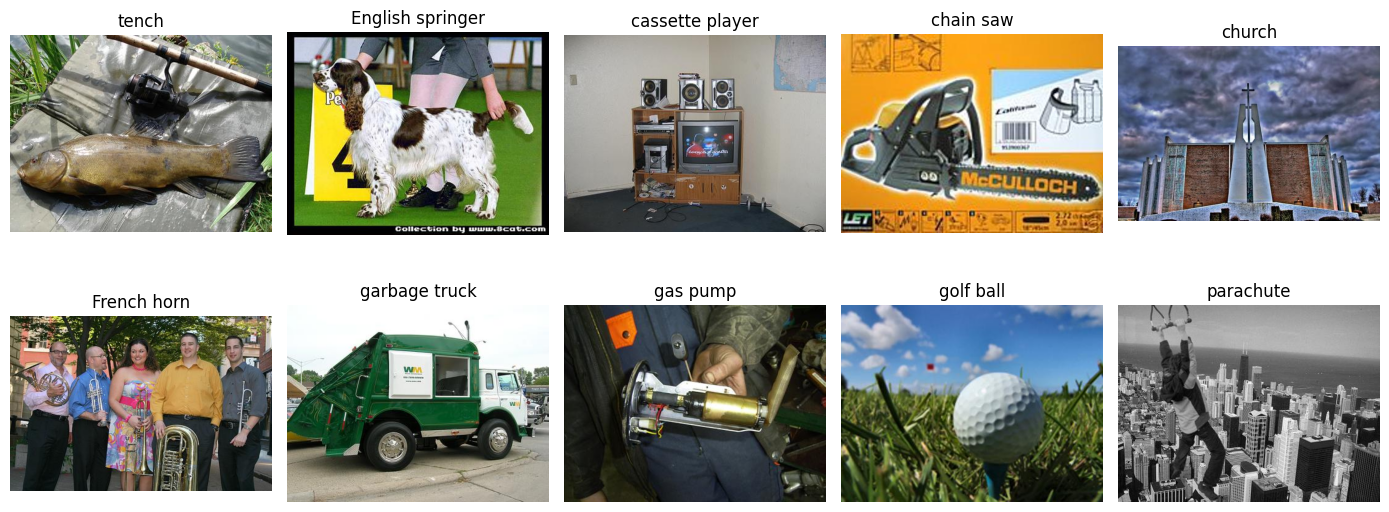

Samples in dataset: 3925


In [4]:
class ImageFolderDataset(Dataset):
    """Loads images from root/<class_folder>/*.jpg and returns (image_tensor, label)."""
    EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

    def __init__(self, root, class_folders, transform=None, max_per_class=None):
        self.transform = transform
        self.class_folders = list(class_folders)
        self.samples = []   # list of (path, label)
        for label, folder in enumerate(self.class_folders):
            files = sorted(p for p in (Path(root) / folder).iterdir() if p.suffix.lower() in self.EXTS)
            if max_per_class:
                files = files[:max_per_class]
            self.samples += [(p, label) for p in files]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")      # handles grayscale / RGBA files
        if self.transform:
            img = self.transform(img)
        return img, label


def make_loader(transform, batch_size=64):
    ds = ImageFolderDataset(IMG_DIR, CLASS_FOLDERS, transform, MAX_PER_CLASS)
    return DataLoader(ds, batch_size=batch_size, shuffle=False,
                      num_workers=2, pin_memory=(DEVICE.type == "cuda"))

# Sanity check: Show a few raw samples
ds_preview = ImageFolderDataset(IMG_DIR, CLASS_FOLDERS, None, MAX_PER_CLASS)
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, i in zip(axes.ravel(), np.linspace(0, len(ds_preview) - 1, 10, dtype=int)):
    img, y = ds_preview[i]
    ax.imshow(img); ax.set_title(CLASS_NAMES[y]); ax.axis("off")
plt.tight_layout(); plt.show()
print("Samples in dataset:", len(ds_preview))

## 4. Models

Five architectures from `torchvision.models`, chosen to span different design families and sizes:

| Model | Family | Idea |
|---|---|---|
| ResNet-50 | CNN | Residual (skip) connections |
| DenseNet-121 | CNN | Dense feature reuse across layers |
| MobileNetV3-Large | Lightweight CNN | Depthwise convolutions, built for mobile |
| EfficientNet-B0 | CNN | Compound scaling of depth/width/resolution |
| ViT-B/16 | Transformer | Image patches + self-attention |

Each model's own `weights.transforms()` is used, so input size, resize, crop and normalization match what the model was trained with.

In [5]:
MODEL_NAMES = ["resnet50", "densenet121", "mobilenet_v3_large", "efficientnet_b0", "vit_b_16"]

def load_model(name):
    weights = models.get_model_weights(name).DEFAULT
    model = models.get_model(name, weights=weights).to(DEVICE).eval()
    return model, weights.transforms()

@torch.no_grad()
def evaluate(name, batch_size=64):
    model, transform = load_model(name)
    loader = make_loader(transform, batch_size)
    n_params = sum(p.numel() for p in model.parameters()) / 1e6

    y_true, y_pred = [], []
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    start = time.time()
    for x, y in loader:
        logits = model(x.to(DEVICE))                    # (B, 1000)
        logits = logits[:, IMAGENET_IDX.to(DEVICE)]      # keep only 10 classes
        y_pred += logits.argmax(1).cpu().tolist()
        y_true += y.tolist()
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    elapsed = time.time() - start

    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": p, "Recall": r, "F1-score": f1,
        "Params (M)": round(n_params, 1),
        "Input size": f"{transform.crop_size[0]}x{transform.crop_size[0]}",
        "ms / image": round(1000 * elapsed / len(y_true), 2),
    }
    return result, np.array(y_true), np.array(y_pred)

results, preds = [], {}
for name in MODEL_NAMES:
    print(f"Evaluating {name} ...")
    res, yt, yp = evaluate(name)
    results.append(res); preds[name] = (yt, yp)
print("Done.")

Evaluating resnet50 ...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 216MB/s]


Evaluating densenet121 ...
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 110MB/s] 


Evaluating mobilenet_v3_large ...
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


...

Evaluating efficientnet_b0 ...
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 157MB/s]


Evaluating vit_b_16 ...
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 148MB/s]


Done.


## 5. Results

In [6]:
df = pd.DataFrame(results).set_index("Model").sort_values("F1-score", ascending=False)
styled = (df.style
          .format({"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1-score": "{:.4f}"})
          .highlight_max(subset=["Accuracy", "Precision", "Recall", "F1-score"], color="lightgreen"))
display(styled)

,Accuracy,Precision,Recall,F1-score,Params (M),Input size,ms / image
Model,,,,,,,
vit_b_16,0.9992,0.9992,0.9992,0.9992,86.600000,224x224,13.350000
resnet50,0.9985,0.9985,0.9984,0.9984,25.600000,224x224,5.270000
efficientnet_b0,0.9982,0.9982,0.9982,0.9982,5.300000,224x224,4.800000
mobilenet_v3_large,0.9962,0.9962,0.9962,0.9962,5.500000,224x224,4.280000
densenet121,0.9936,0.9937,0.9936,0.9936,8.000000,224x224,4.880000


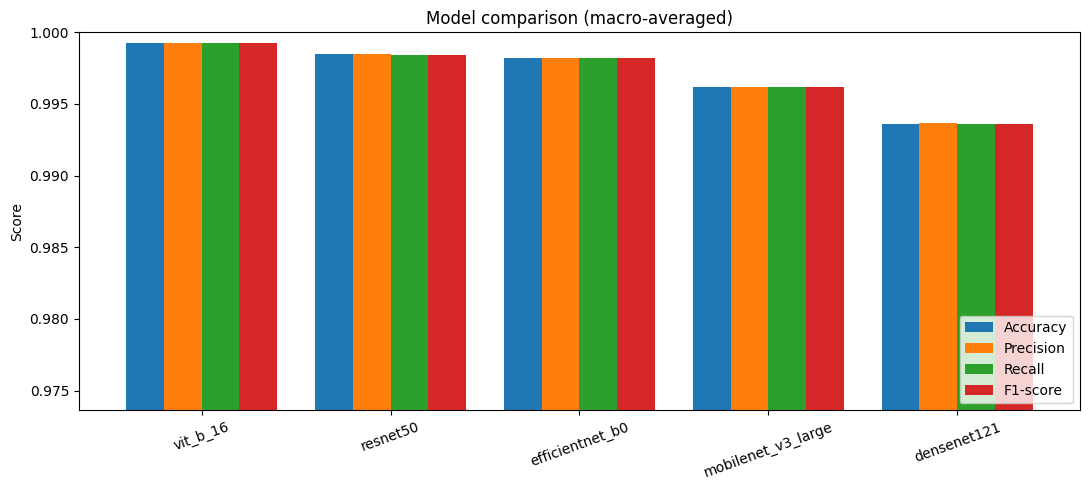

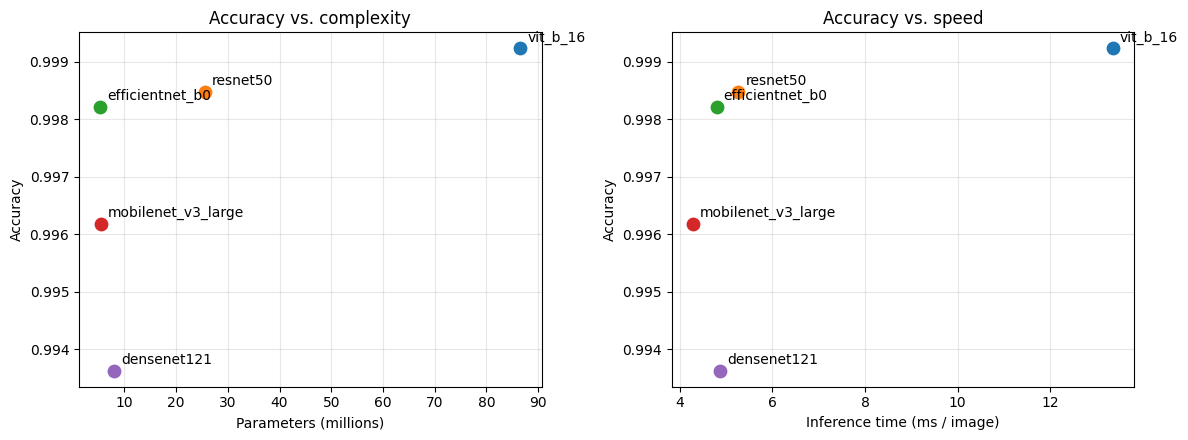

In [7]:
# Visualization 1: grouped bar chart of the four metrics
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
ax = df[metrics].plot(kind="bar", figsize=(11, 5), width=0.8)
ax.set_ylim(df[metrics].min().min() - 0.02, 1.0)
ax.set_title("Model comparison (macro-averaged)"); ax.set_ylabel("Score"); ax.set_xlabel("")
plt.xticks(rotation=20); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

# Visualization 2: accuracy vs. model size and speed
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, row in df.iterrows():
    axes[0].scatter(row["Params (M)"], row["Accuracy"], s=80); axes[0].annotate(name, (row["Params (M)"], row["Accuracy"]), xytext=(5, 5), textcoords="offset points")
    axes[1].scatter(row["ms / image"], row["Accuracy"], s=80); axes[1].annotate(name, (row["ms / image"], row["Accuracy"]), xytext=(5, 5), textcoords="offset points")
axes[0].set_xlabel("Parameters (millions)"); axes[1].set_xlabel("Inference time (ms / image)")
for a in axes: a.set_ylabel("Accuracy"); a.grid(alpha=.3)
axes[0].set_title("Accuracy vs. complexity"); axes[1].set_title("Accuracy vs. speed")
plt.tight_layout(); plt.show()

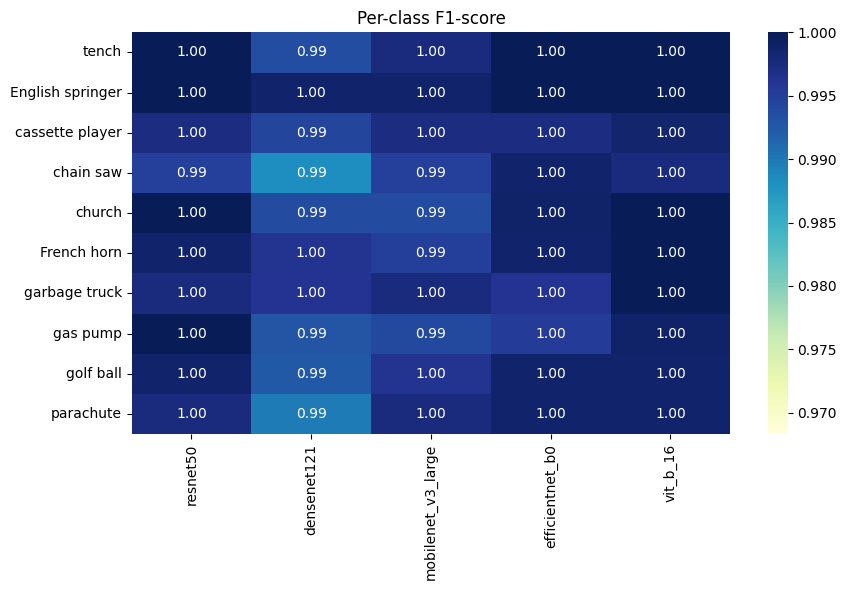

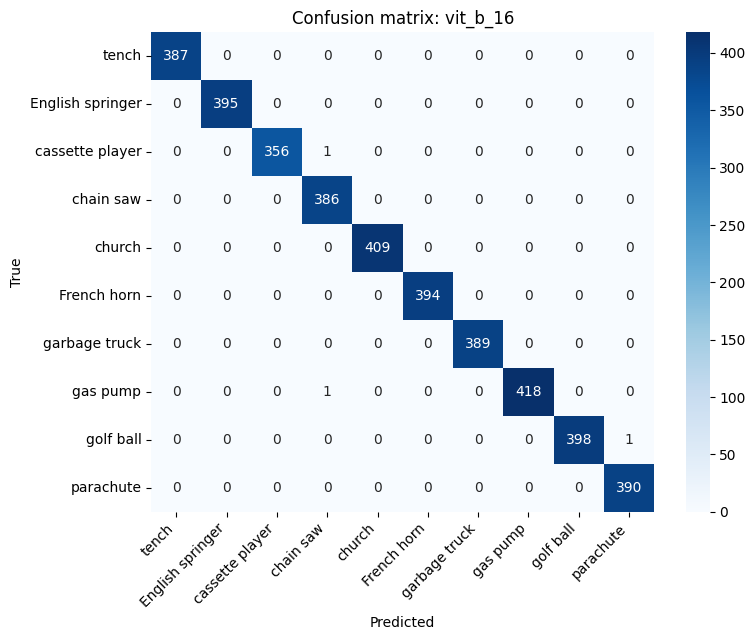

                  precision    recall  f1-score   support

           tench      1.000     1.000     1.000       387
English springer      1.000     1.000     1.000       395
 cassette player      1.000     0.997     0.999       357
       chain saw      0.995     1.000     0.997       386
          church      1.000     1.000     1.000       409
     French horn      1.000     1.000     1.000       394
   garbage truck      1.000     1.000     1.000       389
        gas pump      1.000     0.998     0.999       419
       golf ball      1.000     0.997     0.999       399
       parachute      0.997     1.000     0.999       390

        accuracy                          0.999      3925
       macro avg      0.999     0.999     0.999      3925
    weighted avg      0.999     0.999     0.999      3925



In [8]:
# Visualization 3: per-class F1 for every model
per_class = {}
for name, (yt, yp) in preds.items():
    _, _, f1, _ = precision_recall_fscore_support(yt, yp, labels=range(len(CLASS_NAMES)), zero_division=0)
    per_class[name] = f1
pc = pd.DataFrame(per_class, index=CLASS_NAMES)
plt.figure(figsize=(9, 6))
sns.heatmap(pc, annot=True, fmt=".2f", cmap="YlGnBu", vmin=pc.values.min() - 0.02, vmax=1)
plt.title("Per-class F1-score"); plt.tight_layout(); plt.show()

# Visualization 4: confusion matrix of the best model
best = df.index[0]
yt, yp = preds[best]
plt.figure(figsize=(8, 6.5))
sns.heatmap(confusion_matrix(yt, yp), annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f"Confusion matrix: {best}"); plt.xlabel("Predicted"); plt.ylabel("True")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

print(classification_report(yt, yp, target_names=CLASS_NAMES, digits=3))

In [9]:
# Comparison table saved just in case
df.to_csv("model_comparison.csv")
print(df.round(4).to_markdown())

| Model              |   Accuracy |   Precision |   Recall |   F1-score |   Params (M) | Input size   |   ms / image |
|:-------------------|-----------:|------------:|---------:|-----------:|-------------:|:-------------|-------------:|
| vit_b_16           |     0.9992 |      0.9992 |   0.9992 |     0.9992 |         86.6 | 224x224      |        13.35 |
| resnet50           |     0.9985 |      0.9985 |   0.9984 |     0.9984 |         25.6 | 224x224      |         5.27 |
| efficientnet_b0    |     0.9982 |      0.9982 |   0.9982 |     0.9982 |          5.3 | 224x224      |         4.8  |
| mobilenet_v3_large |     0.9962 |      0.9962 |   0.9962 |     0.9962 |          5.5 | 224x224      |         4.28 |
| densenet121        |     0.9936 |      0.9937 |   0.9936 |     0.9936 |          8   | 224x224      |         4.88 |


## 6. Analysis and Conclusion

### 6.1 Overall results

 All five models did very well on Imagenette, scoring above 99% on every metric. ViT-B/16 ranked first (accuracy and F1 of 0.9992, about 3 mistakes out of 3,925 images), followed by ResNet-50 (0.9985), EfficientNet-B0 (0.9982), and MobileNetV3-Large (0.9962). DenseNet-121 ranked last (0.9936, about 25 mistakes). The whole spread is only about 0.6 percentage points. Precision, recall, and F1 are almost identical for each model because the classes are balanced (357 to 419 images each) and the mistakes were spread out evenly.

The top three models differ by only a few images (roughly 3, 6, and 7 mistakes), so their ranking should not be over-read. Only DenseNet-121 and, to a lesser extent, MobileNetV3-Large clearly trailed.

**Why the results differed.**

- **Architecture:** ViT-B/16 uses self-attention across the whole image, which helps it relate distant parts of a scene, such as an object against a cluttered background. ResNet-50 relies on skip connections that preserve useful features in a deep network, and EfficientNet-B0 balances depth, width, and resolution carefully. The final ranking matches the models' published ImageNet-1k accuracy: ViT-B/16 and ResNet-50 are around 81%, EfficientNet-B0 around 78%, and MobileNetV3-Large and DenseNet-121 around 74 to 75%. A model that is better on ImageNet is also better on its subset.


- **Model complexity:** More parameters did not buy much. ViT-B/16 has 86.6M parameters and took 13.35 ms per image, about 2.5 to 3 times slower than the others (4.3 to 5.3 ms). EfficientNet-B0 has only 5.3M parameters (about 16 times fewer than ViT) yet scored just 0.001 lower in accuracy than ResNet-50, which has 25.6M. DenseNet-121 has few parameters (8M) but was not faster than EfficientNet-B0, likely because its dense connections reuse many feature maps, which costs time and memory.


- **Input requirements:** All five models end up with 224x224 inputs, so image resolution does not explain the differences. Each model used its own recommended resizing and normalization, which keeps the comparison fair. Note that the pre-trained weights also come from different training recipes, so the results reflect architecture and training together.
- **Suitability for the dataset:** Every Imagenette class exists in ImageNet-1k, and limiting predictions to 10 classes makes the task easier than the original 1,000-way problem. The classes are also visually distinct. Almost every per-class F1 is 0.99 or higher. Chain saw was among the lowest for several models, and it received two of ViT's three mistakes (a cassette player and a gas pump predicted as chain saw). A possible reason is that chain saws appear in varied, cluttered scenes and share boxy shapes and handles with other objects, although this was not tested.

### 6.2 Limitations

Imagenette is built from ImageNet images, so the models may have seen some of these images during training, which can make the scores look better than they would on completely new images. The speed numbers include image loading time and depend on the Colab GPU used. The study uses one dataset, one validation split, and no fine-tuning.

### 6.3 Conclusion

 ViT-B/16 was the most accurate model, but it is the largest and slowest. EfficientNet-B0 offers the best balance: about 0.998 accuracy with 5.3M parameters, roughly 2.8 times faster than ViT-B/16. ResNet-50 is a strong middle option. For the highest accuracy, ViT-B/16 is the better choice. For mobile or limited hardware, EfficientNet-B0 or MobileNetV3-Large would be my recommendation. Because all five models scored so high, speed, size, and available hardware matter more than accuracy when choosing among them for this dataset.